# Loan Approval Analysis
### Project objective

To identify which applicant and loan characteristics have the clearest relationship with loan approval in this dataset.

> This is an exploratory data analysis. It identifies associations in the supplied dataset; it does not prove causation or reproduce a bank's lending policy.


## 1. Import libraries and load the dataset


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.facecolor": "#F4F7FA",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": "#CDD5DF",
    "text.color": "#17263C",
    "axes.labelcolor": "#536174",
    "xtick.color": "#697586",
    "ytick.color": "#697586",
    "figure.dpi": 120,
    "savefig.dpi": 170,
})

GREEN = "#16866F"
RED = "#D95C64"
BLUE = "#3478B8"
GOLD = "#C28A32"
NAVY = "#17263C"
MUTED = "#697586"
GRID = "#E4E9EF"
STATUS = ["Approved", "Rejected"]



raw = pd.read_csv("loan_approval_dataset.csv")
raw.columns = raw.columns.str.strip()
for column in raw.select_dtypes(include=["object", "str"]):
    raw[column] = raw[column].astype("string").str.strip()

print(f"Dataset loaded: {raw.shape[0]:,} rows and {raw.shape[1]} columns")


Dataset loaded: 4,269 rows and 13 columns


## 2. Data-quality checks and feature preparation


In [2]:
# Create a working copy
df = raw.copy()

STATUS = ["Approved", "Rejected"]

asset_columns = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value",
]

# Correct negative asset values
negative_asset_cells = int(
    (df[asset_columns] < 0).sum().sum()
)

for column in asset_columns:
    valid_median = df.loc[
        df[column] >= 0, column
    ].median()

    df.loc[
        df[column] < 0, column
    ] = valid_median

# Validate loan-status values
if not df["loan_status"].isin(STATUS).all():
    raise ValueError(
        "Unexpected loan_status value found."
    )

# Create analytical columns
df["approved"] = (
    df["loan_status"]
    .eq("Approved")
    .astype(int)
)

df["income_lakhs"] = (
    df["income_annum"] / 100_000
)

df["loan_lakhs"] = (
    df["loan_amount"] / 100_000
)

df["total_assets"] = (
    df[asset_columns].sum(axis=1)
)

df["assets_lakhs"] = (
    df["total_assets"] / 100_000
)

overall_approval = (
    df["approved"].mean() * 100
)

print(f"Total applications: {len(df):,}")
print(
    f"Negative asset values corrected: "
    f"{negative_asset_cells}"
)
print(
    f"Overall approval rate: "
    f"{overall_approval:.1f}%"
)

Total applications: 4,269
Negative asset values corrected: 28
Overall approval rate: 62.2%


**Cleaning decision:** The dataset contains 28 negative asset entries. Because a reported asset value cannot be negative, each invalid value is replaced by the median of the valid values in that same asset column. This is why negative asset outliers do not appear in the later charts.


## 3. Helper functions and analytical bands


In [3]:
def approval_table(column, order=None):
    table = (
        df.groupby(column, observed=True)["approved"]
          .agg(applications="size", approved="sum")
    )
    table["rejected"] = table["applications"] - table["approved"]
    table["approval_rate"] = table["approved"] / table["applications"] * 100
    table["rejection_rate"] = 100 - table["approval_rate"]
    if order is not None:
        table = table.reindex(order)
    return table


def clean_axis(ax, percent=True, grid_axis="y"):
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.9)
    ax.tick_params(axis="both", length=0, pad=7)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#CDD5DF")
    if percent:
        ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))


def single_rate_bars(table, labels, title, xlabel):
    x = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(12.5, 6.1), layout="constrained")
    bars = ax.bar(
        x,
        table["approval_rate"],
        width=0.58,
        color=GREEN,
        edgecolor="white",
        linewidth=1.4,
        zorder=3,
    )
    ax.bar_label(
        bars,
        labels=[f"{value:.1f}%" for value in table["approval_rate"]],
        padding=6,
        fontsize=12,
        fontweight="bold",
        color=NAVY,
    )
    ax.axhline(
        overall_approval,
        color=RED,
        linewidth=2,
        linestyle=(0, (5, 4)),
        label=f"Overall approval: {overall_approval:.1f}%",
    )
    ax.set_title(title, pad=18)
    ax.set_xlabel(xlabel, labelpad=12, fontweight="bold")
    ax.set_ylabel("Approval rate", fontweight="bold")
    ax.set_xticks(x, labels)
    ax.set_ylim(0, 80)
    ax.set_yticks([0, 20, 40, 60, 80])
    clean_axis(ax)
    ax.legend(loc="upper left", frameon=False)
    plt.show()


def quartile_band(source, target):
    df[target], edges = pd.qcut(
        df[source], q=4, labels=["Q1", "Q2", "Q3", "Q4"], retbins=True
    )
    return edges


def range_labels(edges):
    labels = []
    for index in range(4):
        lower = f"{edges[index]:.0f}"
        upper = f"{edges[index + 1]:.0f}"
        prefix = ">" if index else ""
        labels.append(f"{prefix}{lower}–{upper}")
    return labels


income_edges = quartile_band("income_lakhs", "income_band")
loan_edges = quartile_band("loan_lakhs", "loan_band")
asset_edges = quartile_band("assets_lakhs", "asset_band")

income_labels = range_labels(income_edges)
loan_labels = range_labels(loan_edges)
asset_labels = range_labels(asset_edges)


Financial ranges are **quartile bands created from this dataset**. Each band contains approximately one-quarter of the applications; these are not official banking categories.


# Selected Visual Analysis


## 4. Overall loan approval


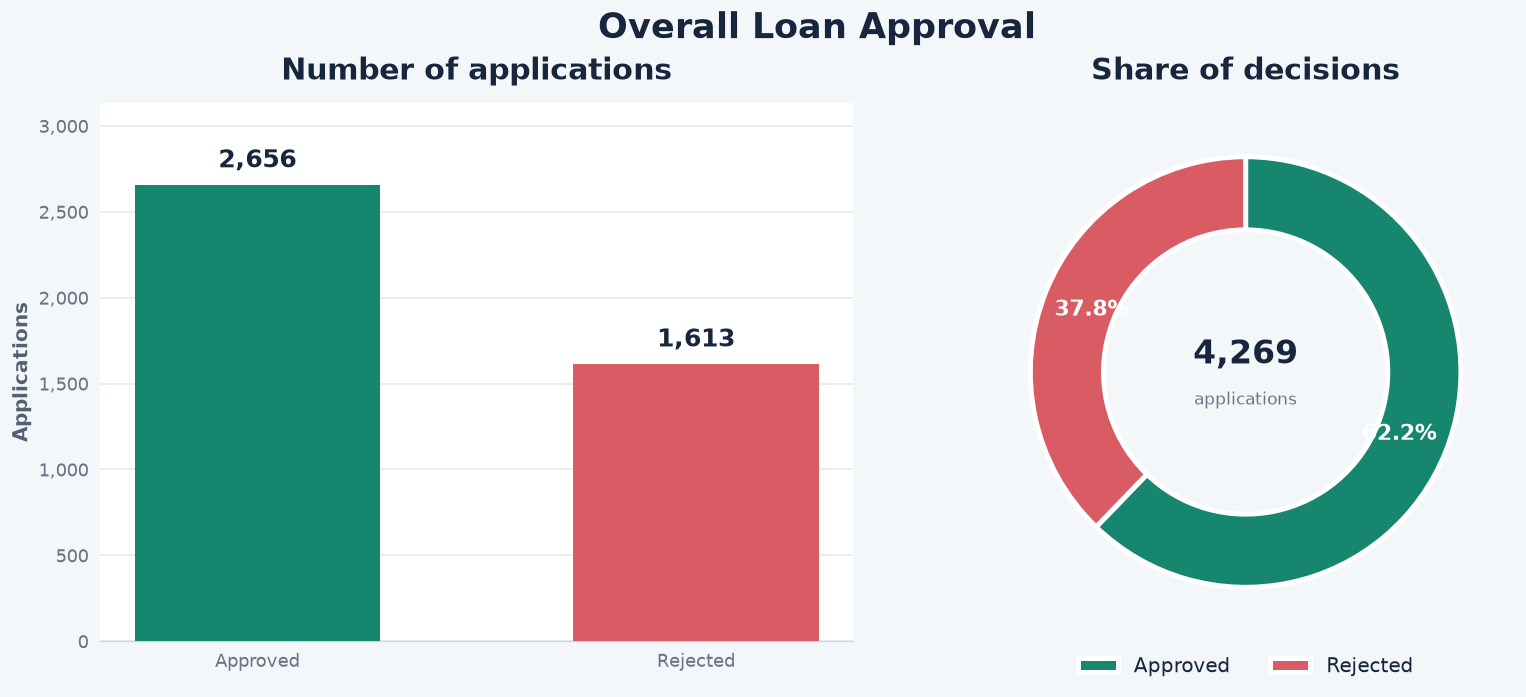

In [4]:
status_counts = df["loan_status"].value_counts().reindex(STATUS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.7), layout="constrained")
fig.suptitle("Overall Loan Approval", fontsize=21, fontweight="bold")

bars = axes[0].bar(STATUS, status_counts, color=[GREEN, RED], width=0.56, zorder=3)
axes[0].bar_label(
    bars,
    labels=[f"{value:,}" for value in status_counts],
    padding=7,
    fontsize=15,
    fontweight="bold",
    color=NAVY,
)
axes[0].set_title("Number of applications", pad=14)
axes[0].set_ylabel("Applications", fontweight="bold")
axes[0].set_ylim(0, status_counts.max() * 1.18)
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
clean_axis(axes[0], percent=False)

wedges, _, percentages = axes[1].pie(
    status_counts,
    colors=[GREEN, RED],
    startangle=90,
    counterclock=False,
    autopct="%1.1f%%",
    pctdistance=0.77,
    wedgeprops={"width": 0.34, "edgecolor": "white", "linewidth": 3},
    textprops={"fontsize": 13, "fontweight": "bold", "color": "white"},
)
axes[1].text(0, 0.08, f"{len(df):,}", ha="center", va="center",
             fontsize=20, fontweight="bold", color=NAVY)
axes[1].text(0, -0.13, "applications", ha="center", va="center",
             fontsize=10, color=MUTED)
axes[1].set_title("Share of decisions", pad=14)
axes[1].legend(wedges, STATUS, loc="lower center", bbox_to_anchor=(0.5, -0.10),
               ncol=2, frameon=False)
plt.show()


**Finding:** 2,656 applications were approved and 1,613 were rejected. The overall approval rate is **62.2%**.


## 5. Loan decisions by CIBIL score range


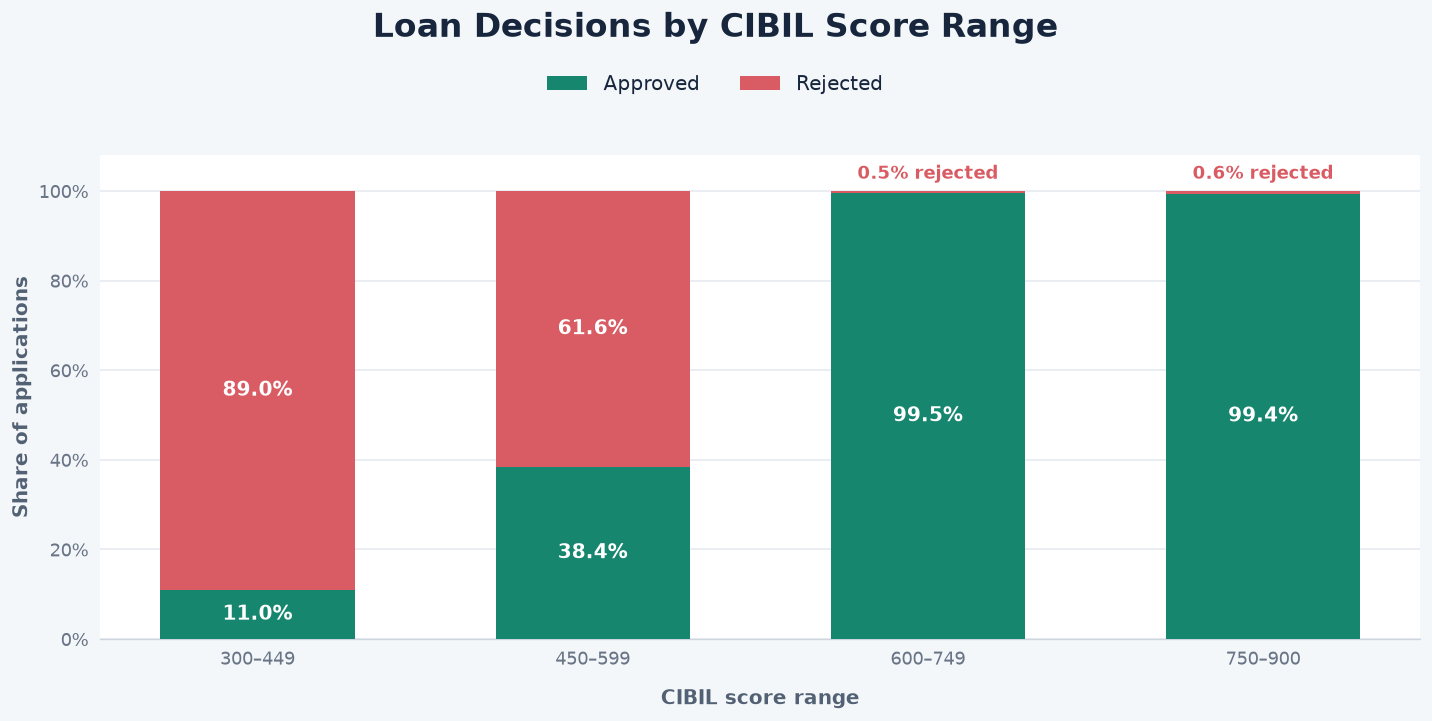

In [5]:
cibil_labels = ["300–449", "450–599", "600–749", "750–900"]
df["cibil_band"] = pd.cut(
    df["cibil_score"],
    bins=[299, 449, 599, 749, 900],
    labels=cibil_labels,
    include_lowest=True,
)
if df["cibil_band"].isna().any():
    raise ValueError("CIBIL score outside the selected analytical ranges.")

cibil = approval_table("cibil_band", cibil_labels)
x = np.arange(len(cibil))

fig, ax = plt.subplots(figsize=(12.5, 6.3))
fig.subplots_adjust(top=0.78, bottom=0.14, left=0.09, right=0.97)
approved_bars = ax.bar(
    x, cibil["approval_rate"], width=0.58, color=GREEN, label="Approved", zorder=3
)
rejected_bars = ax.bar(
    x,
    cibil["rejection_rate"],
    bottom=cibil["approval_rate"],
    width=0.58,
    color=RED,
    label="Rejected",
    zorder=3,
)

for position, approved, rejected in zip(
    x, cibil["approval_rate"], cibil["rejection_rate"]
):
    if approved >= 8:
        ax.text(position, approved / 2, f"{approved:.1f}%", ha="center", va="center",
                color="white", fontsize=12, fontweight="bold")
    else:
        ax.text(position, approved + 2, f"{approved:.1f}%", ha="center", va="bottom",
                color=GREEN, fontsize=11, fontweight="bold")
    if rejected >= 8:
        ax.text(position, approved + rejected / 2, f"{rejected:.1f}%", ha="center",
                va="center", color="white", fontsize=12, fontweight="bold")
    else:
        ax.text(position, 101.8, f"{rejected:.1f}% rejected", ha="center", va="bottom",
                color=RED, fontsize=10.5, fontweight="bold", clip_on=False)

fig.suptitle("Loan Decisions by CIBIL Score Range", y=0.97,
             fontsize=20, fontweight="bold")
ax.set_xlabel("CIBIL score range", labelpad=12, fontweight="bold")
ax.set_ylabel("Share of applications", fontweight="bold")
ax.set_xticks(x, cibil_labels)
ax.set_ylim(0, 108)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
clean_axis(ax)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=2, frameon=False)
plt.show()


**Finding:** CIBIL score has the clearest relationship with approval. Approval rises from **11.0%** for scores 300–449 and **38.4%** for 450–599 to more than **99%** for both ranges above 600.

**Note:** These score ranges were created for this project and are not official CIBIL risk grades.


## 6. Approval rate by loan term


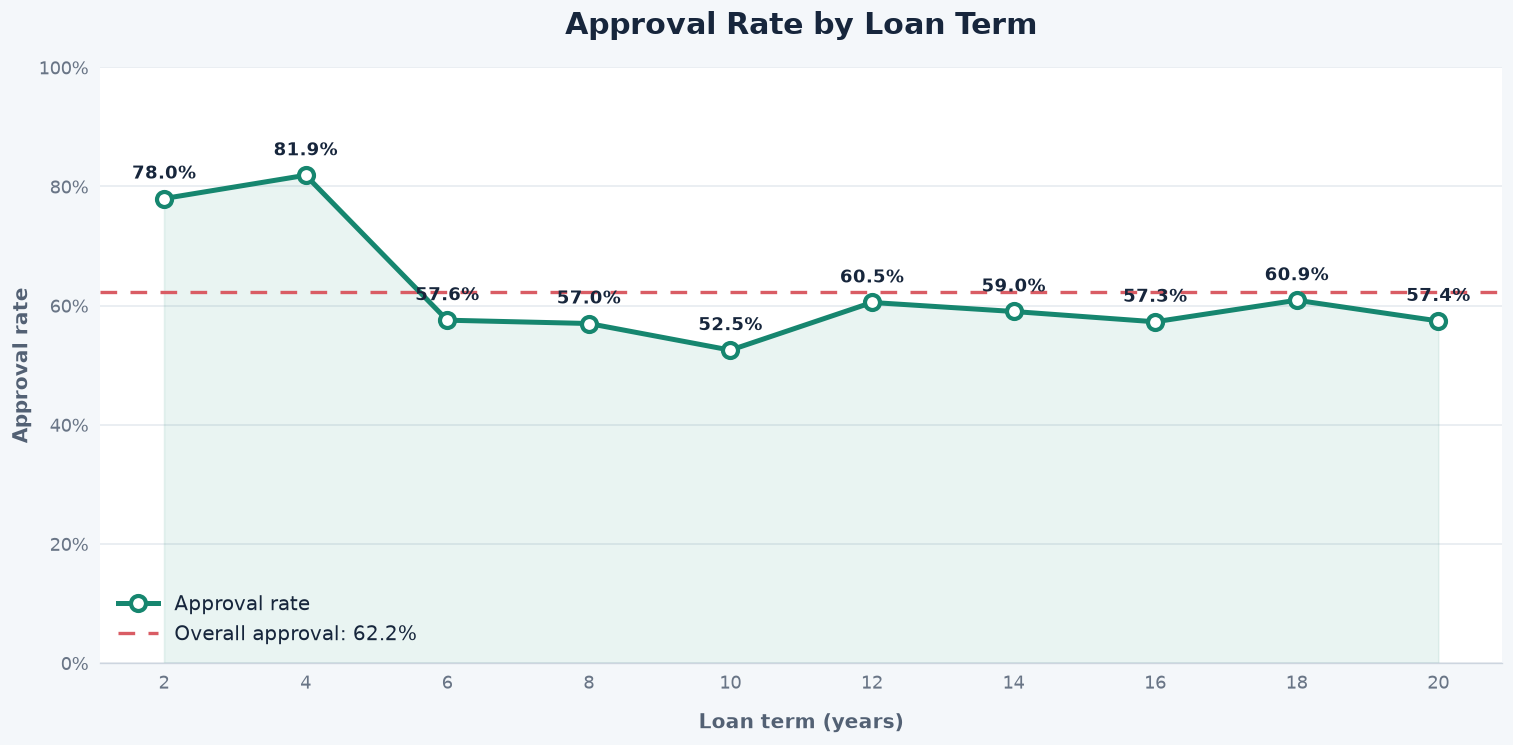

In [6]:
loan_term = approval_table("loan_term").sort_index()

fig, ax = plt.subplots(figsize=(12.5, 6.1), layout="constrained")
ax.plot(
    loan_term.index,
    loan_term["approval_rate"],
    color=GREEN,
    linewidth=3,
    marker="o",
    markersize=9,
    markerfacecolor="white",
    markeredgewidth=2.5,
    markeredgecolor=GREEN,
    label="Approval rate",
    zorder=3,
)
ax.fill_between(loan_term.index, loan_term["approval_rate"], color=GREEN, alpha=0.09)
ax.axhline(
    overall_approval,
    color=RED,
    linewidth=2,
    linestyle=(0, (5, 4)),
    label=f"Overall approval: {overall_approval:.1f}%",
)

for term, rate in zip(loan_term.index, loan_term["approval_rate"]):
    ax.annotate(
        f"{rate:.1f}%",
        (term, rate),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10.5,
        fontweight="bold",
        color=NAVY,
    )

ax.set_title("Approval Rate by Loan Term", pad=20)
ax.set_xlabel("Loan term (years)", labelpad=12, fontweight="bold")
ax.set_ylabel("Approval rate", fontweight="bold")
ax.set_xticks(loan_term.index)
ax.set_ylim(0, 100)
ax.set_yticks([0, 20, 40, 60, 80, 100])
clean_axis(ax)
ax.legend(loc="lower left", frameon=False)
plt.show()


**Finding:** Four-year loans have the highest approval rate (**81.9%**), followed by two-year loans (**78.0%**). Rates for most terms from 6 to 20 years are closer to 53–61%.


## 7. Distribution of key financial values


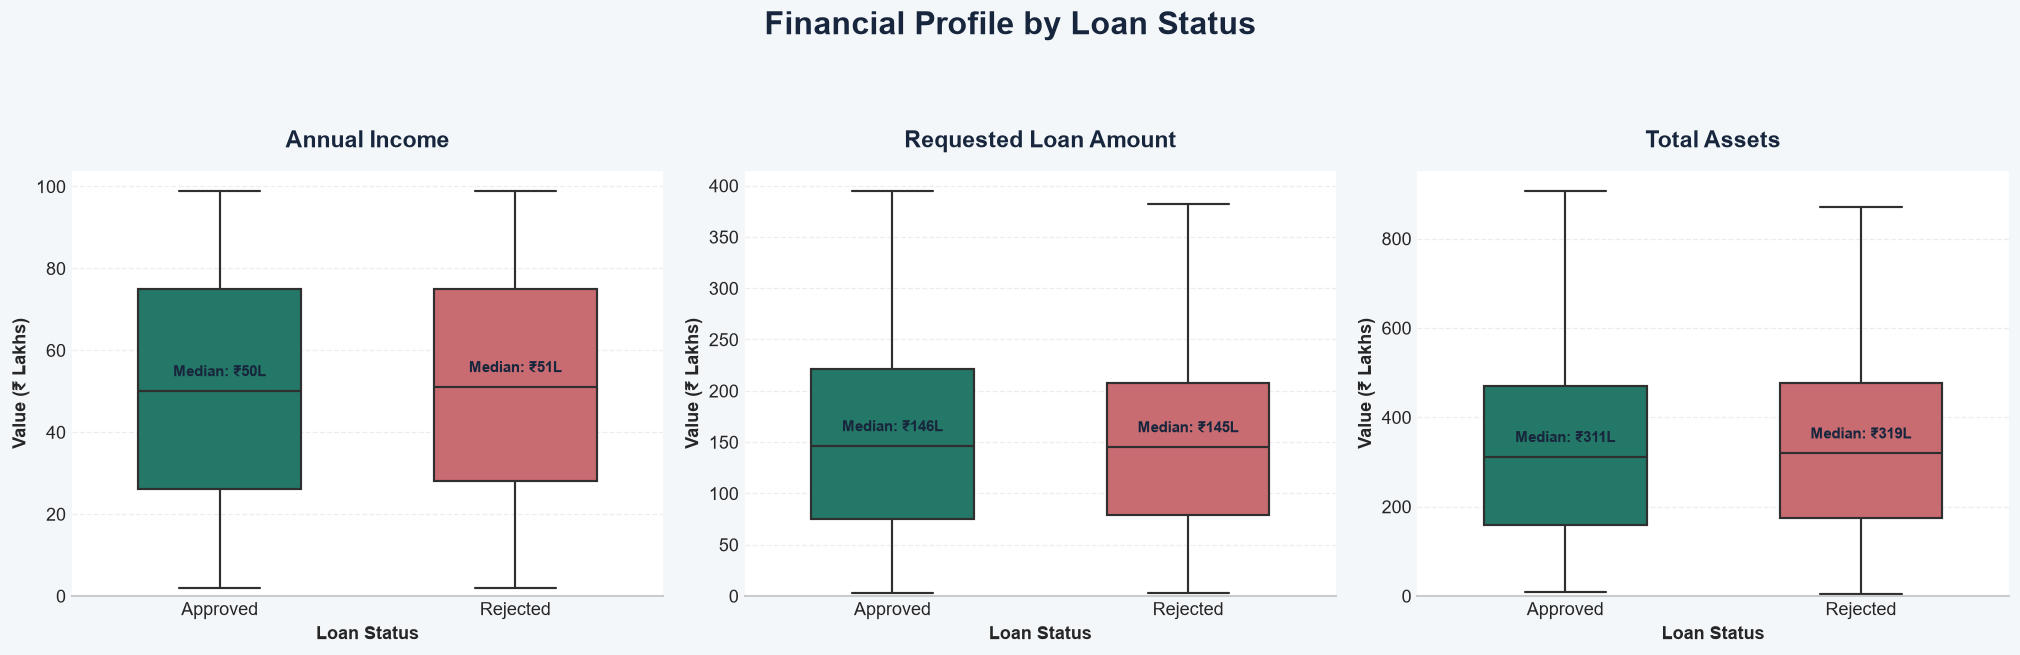

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create values in ₹ lakhs
df["income_lakhs"] = df["income_annum"] / 100_000
df["loan_amount_lakhs"] = df["loan_amount"] / 100_000

asset_columns = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

df["total_assets_lakhs"] = (
    df[asset_columns].sum(axis=1) / 100_000
)

df["loan_status"] = df["loan_status"].str.strip()

APPROVAL_COLORS = {
    "Approved": "#16866F",
    "Rejected": "#D95C64"
}

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.5),
    facecolor="#F4F7FA"
)

plots = [
    ("income_lakhs", "Annual Income"),
    ("loan_amount_lakhs", "Requested Loan Amount"),
    ("total_assets_lakhs", "Total Assets")
]

status_order = ["Approved", "Rejected"]

for ax, (column, title) in zip(axes, plots):

    sns.boxplot(
        data=df,
        x="loan_status",
        y=column,
        order=status_order,
        hue="loan_status",
        hue_order=status_order,
        palette=APPROVAL_COLORS,
        width=0.55,
        linewidth=1.3,
        fliersize=3,
        legend=False,
        ax=ax
    )

    # Add median labels
    medians = (
        df.groupby("loan_status")[column]
        .median()
        .reindex(status_order)
    )

    for position, median in enumerate(medians):
        ax.annotate(
            f"Median: ₹{median:.0f}L",
            xy=(position, median),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="bold",
            color="#17263C"
        )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        color="#17263C",
        pad=14
    )

    ax.set_xlabel(
        "Loan Status",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Value (₹ Lakhs)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylim(bottom=0)

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.8,
        alpha=0.35
    )

    ax.tick_params(axis="both", length=0)

    for border in ["top", "right", "left"]:
        ax.spines[border].set_visible(False)

fig.suptitle(
    "Financial Profile by Loan Status",
    fontsize=19,
    fontweight="bold",
    color="#17263C",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

**Finding:** Requested loan amounts and total assets have a wider spread than annual income. Red points, where present, are statistical outliers after invalid negative asset entries have been corrected.


## 11. Education and self-employment


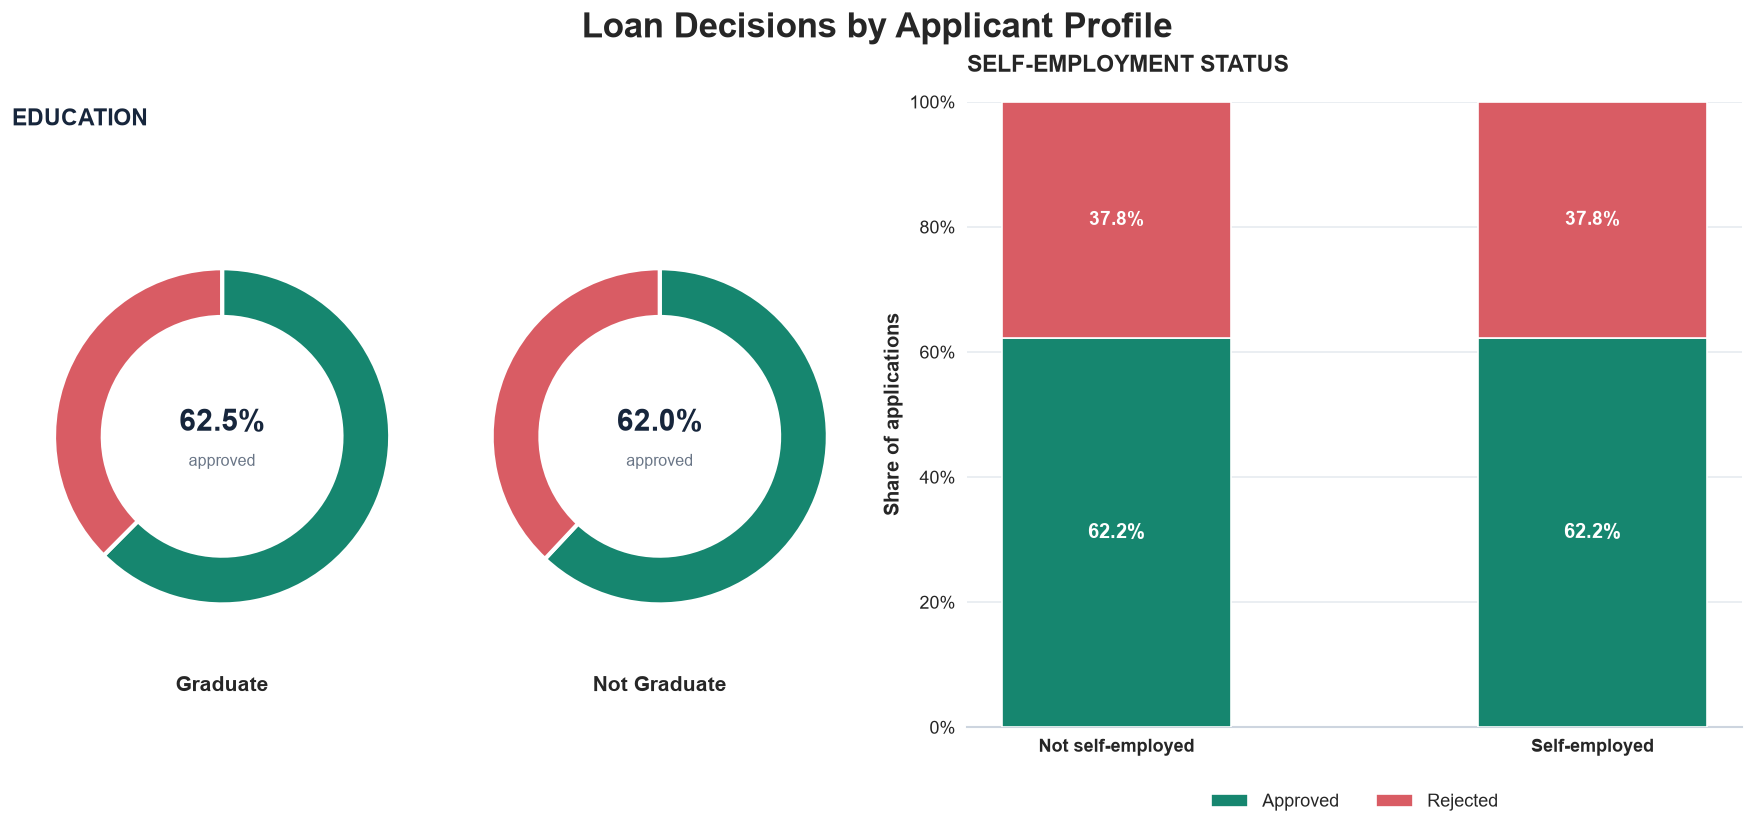

In [8]:
education = approval_table("education", ["Graduate", "Not Graduate"])
employment = approval_table("self_employed", ["No", "Yes"])

fig = plt.figure(figsize=(14.5, 6.8), layout="constrained")
fig.suptitle("Loan Decisions by Applicant Profile", fontsize=21, fontweight="bold")
outer = fig.add_gridspec(1, 2, width_ratios=[1.12, 1.0])
education_grid = outer[0].subgridspec(1, 2)
education_axes = [fig.add_subplot(education_grid[0, 0]), fig.add_subplot(education_grid[0, 1])]
employment_ax = fig.add_subplot(outer[1])

education_labels = ["Graduate", "Not Graduate"]
for ax, label in zip(education_axes, education_labels):
    approved = education.loc[label, "approval_rate"]
    rejected = education.loc[label, "rejection_rate"]
    ax.pie(
        [approved, rejected],
        startangle=90,
        counterclock=False,
        colors=[GREEN, RED],
        wedgeprops={"width": 0.29, "edgecolor": "white", "linewidth": 2.5},
    )
    ax.text(0, 0.08, f"{approved:.1f}%", ha="center", va="center",
            fontsize=18, fontweight="bold", color=NAVY)
    ax.text(0, -0.15, "approved", ha="center", va="center", fontsize=9.5, color=MUTED)
    ax.set_title(label, y=-0.13, fontsize=12.5, fontweight="bold")

education_axes[0].text(
    0.0, 1.24, "EDUCATION", transform=education_axes[0].transAxes,
    fontsize=14, fontweight="bold", color=NAVY
)

employment_keys = ["No", "Yes"]
employment_labels = ["Not self-employed", "Self-employed"]
approved = employment.loc[employment_keys, "approval_rate"].to_numpy()
rejected = employment.loc[employment_keys, "rejection_rate"].to_numpy()
x = np.arange(2)

employment_ax.bar(x, approved, width=0.48, color=GREEN, label="Approved", zorder=3)
employment_ax.bar(x, rejected, width=0.48, bottom=approved, color=RED,
                  label="Rejected", zorder=3)
for position, approved_rate, rejected_rate in zip(x, approved, rejected):
    employment_ax.text(position, approved_rate / 2, f"{approved_rate:.1f}%",
                       ha="center", va="center", color="white",
                       fontsize=12, fontweight="bold")
    employment_ax.text(position, approved_rate + rejected_rate / 2,
                       f"{rejected_rate:.1f}%", ha="center", va="center",
                       color="white", fontsize=11.5, fontweight="bold")

employment_ax.set_title("SELF-EMPLOYMENT STATUS", loc="left", pad=18,
                        fontsize=14, fontweight="bold")
employment_ax.set_xticks(x, employment_labels, fontsize=10.5, fontweight="bold")
employment_ax.set_ylabel("Share of applications", fontweight="bold")
employment_ax.set_ylim(0, 100)
employment_ax.set_yticks([0, 20, 40, 60, 80, 100])
clean_axis(employment_ax)
employment_ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.16),
                     ncol=2, frameon=False)
plt.show()


**Finding:** Graduate and non-graduate applicants have approval rates of **62.5% and 62.0%**. Applicants marked self-employed and not self-employed both have approval rates of approximately **62.2%**. These variables show almost no separation in loan decisions.


## 12. Loan decisions by number of dependents


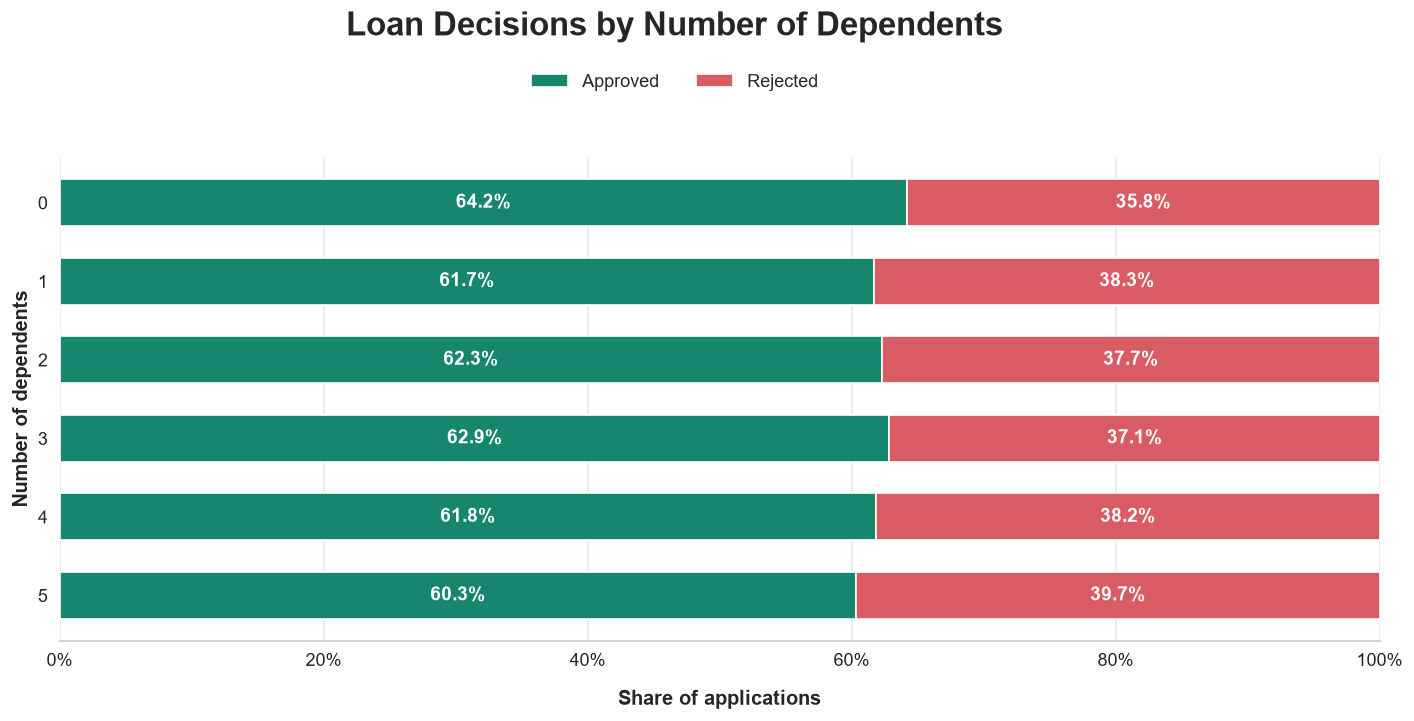

In [9]:
dependents = approval_table("no_of_dependents", list(range(6)))
y = np.arange(len(dependents))

fig, ax = plt.subplots(figsize=(12.5, 6.4))
fig.subplots_adjust(top=0.78, bottom=0.15, left=0.09, right=0.97)
ax.barh(y, dependents["approval_rate"], height=0.60, color=GREEN,
        label="Approved", zorder=3)
ax.barh(y, dependents["rejection_rate"], left=dependents["approval_rate"],
        height=0.60, color=RED, label="Rejected", zorder=3)

for position, approved, rejected in zip(
    y, dependents["approval_rate"], dependents["rejection_rate"]
):
    ax.text(approved / 2, position, f"{approved:.1f}%", ha="center", va="center",
            color="white", fontsize=11.5, fontweight="bold")
    ax.text(approved + rejected / 2, position, f"{rejected:.1f}%", ha="center",
            va="center", color="white", fontsize=11.5, fontweight="bold")

fig.suptitle("Loan Decisions by Number of Dependents", y=0.97,
             fontsize=20, fontweight="bold")
ax.set_xlabel("Share of applications", labelpad=12, fontweight="bold")
ax.set_ylabel("Number of dependents", fontweight="bold")
ax.set_yticks(y, [str(value) for value in dependents.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
clean_axis(ax, percent=False, grid_axis="x")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=2, frameon=False)
plt.show()


**Finding:** Approval ranges from **60.3% to 64.2%** across dependent groups. The differences are small, with no consistent increase or decrease as dependents rise.


# Final Findings and Conclusion

## Main findings

1. **CIBIL score is the strongest separator** among the variables analysed. Approval exceeds 99% in both score ranges above 600.
2. **Loan term shows a secondary pattern.** Two- and four-year loans have noticeably higher approval rates than most longer terms.
3. **Requested loan amount, annual income and total assets show only small and inconsistent differences** across their quartile bands.
4. **Education and self-employment show almost no difference** in approval rate.
5. **Number of dependents has only a small relationship** with approval in this dataset.

## Final conclusion

> **CIBIL score has the clearest relationship with loan approval in this dataset. Loan term shows a smaller pattern, while income, requested loan amount, total assets, education, self-employment and number of dependents do not individually explain the decision well.**

## Important limitation

The dataset contains approval decisions but no later repayment or default outcome. Therefore, this analysis explains **approval patterns**, not whether an applicant is genuinely low-risk or high-risk.
